In [2]:
import scanpy as sc
import pandas as pd
import numpy as np
import os
import re
import anndata as ad
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import zscore

In [3]:
df_query = pd.read_csv('/scratch/nsnyderm/u01/intermediate_files/nebula/age/all_mashr_summary_lfsr<0.05_filter_missing.csv',index_col=0)

In [23]:
#open AD overlap dataframe
df = pd.read_csv('/home/wyang114/output/transcriptional/ad_overlap/overlap_summary_direction_0.001.csv')
ct = 'HIP-DG-Glut'
group = 'glutamatergic neurons'
direction='down'
#select convergent AD genes overlapping between matching cell classes across regions
geneset_str = df.loc[(df['macaque_ct'] == group) & (df['match'] == 'self') & (df['direction'] == direction), 'genelist'].values[0]
geneset = geneset_str.split(',')
print(len(geneset))

# # #filter to those significant in this subtype/celltype
# subtype_list = ['glutamatergic neurons_5','glutamatergic neurons_0','glutamatergic neurons_17',
#                'glutamatergic neurons_17','glutamatergic neurons_27','glutamatergic neurons_29',
#                'glutamatergic neurons_16','glutamatergic neurons_24','glutamatergic neurons_30']
# region_list = ['ACC','dlPFC','IPP','M1']
subtype_list =['glutamatergic neurons_9']
region_list = ['HIP']
df_subset = df_query.loc[(df_query['subtype'].isin(subtype_list)) & (df_query['direction']==direction),:]
#df_subset = df_query.loc[(df_query['celltype']==ct) & (df_query['direction']==direction),:]
#df_subset = df_subset.loc[(abs(df_subset['age_mashr_pm'])>=0.005),:]
df_subset['region'].value_counts()
geneset = list(set(geneset) & set(df_subset['external_gene_name']))
print(len(geneset))

1996
250


In [44]:
# #open AD dataframe
# df = pd.read_csv('/home/wyang114/data/AD_genesets/sc_all_deg_summary_region.csv',index_col=0)
# ct = 'L2-3-IT'
# group = 'exc'
# direction='down'
# lfc_thre=1
# #select convergent AD genes overlapping between matching cell classes across regions
# geneset = df.loc[(df['ct_label'] == group) & (df['direction'] == direction) & (np.abs(df['LFC'])>=lfc_thre), 'macaque.gene.name'].unique()
# print(len(geneset))

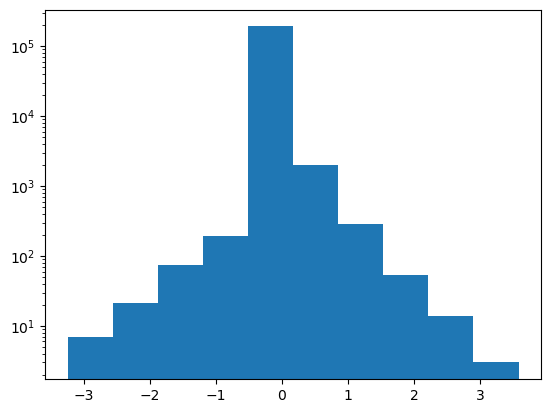

In [10]:
# import matplotlib.pyplot as plt
# plt.hist(df.loc[(df['ct_label'] == group),'LFC'])
# plt.yscale('log') 

In [9]:
##open pseudobulk mat and meta
#mat = pd.read_csv(f'./pseudobulk/{ct}_mat.csv',index_col=0)
#meta = pd.read_csv(f'./pseudobulk/{ct}_meta.csv',index_col=1).iloc[:,1:]
#var_info = pd.read_csv('/scratch/nsnyderm/u01/intermediate_files/cell-class_h5ad_update/all_regions_var.csv',index_col=0)

In [10]:
# #subset genes 
# var = var_info.loc[var_info['external_gene_name'].isin(geneset),:]
# geneset_ensembl = var['ensembl_gene_id'].values
# mat = mat.loc[:,geneset_ensembl]
# #normalize sequencing depth for each sample
# adata = ad.AnnData(X=mat, obs=meta, var=var)
# sc.pp.normalize_total(adata, target_sum=1e4)
# sc.pp.log1p(adata)
# num_genes = len(var)

In [11]:
num_genes

147

## region agnostic

In [66]:
#average individuals within age groups
# Convert to DataFrame for easy grouping (optional, but clearer)
bins=[0,5,10,15,20]
#labels=
adata.obs['age_group'] = pd.cut(adata.obs['age'], bins=bins, right=False)
df_expr = pd.DataFrame(adata.X.toarray() if hasattr(adata.X, 'toarray') else adata.X,
                       index=adata.obs_names,
                       columns=adata.var_names)

# Add metadata
df_expr['animal_id'] = adata.obs['animal_id'].values
df_expr['age_group'] = adata.obs['age_group'].values

# Group by individual and take mean across cells
individual_avg = df_expr.groupby('age_group').apply(lambda x: x.iloc[:, :num_genes].mean())

/home/wyang114/.conda/envs/TACCO_env/lib/python3.11/site-packages/seaborn/matrix.py:560: UserWarning: Clustering large matrix with scipy. Installing `fastcluster` may give better performance.
  warnings.warn(msg)


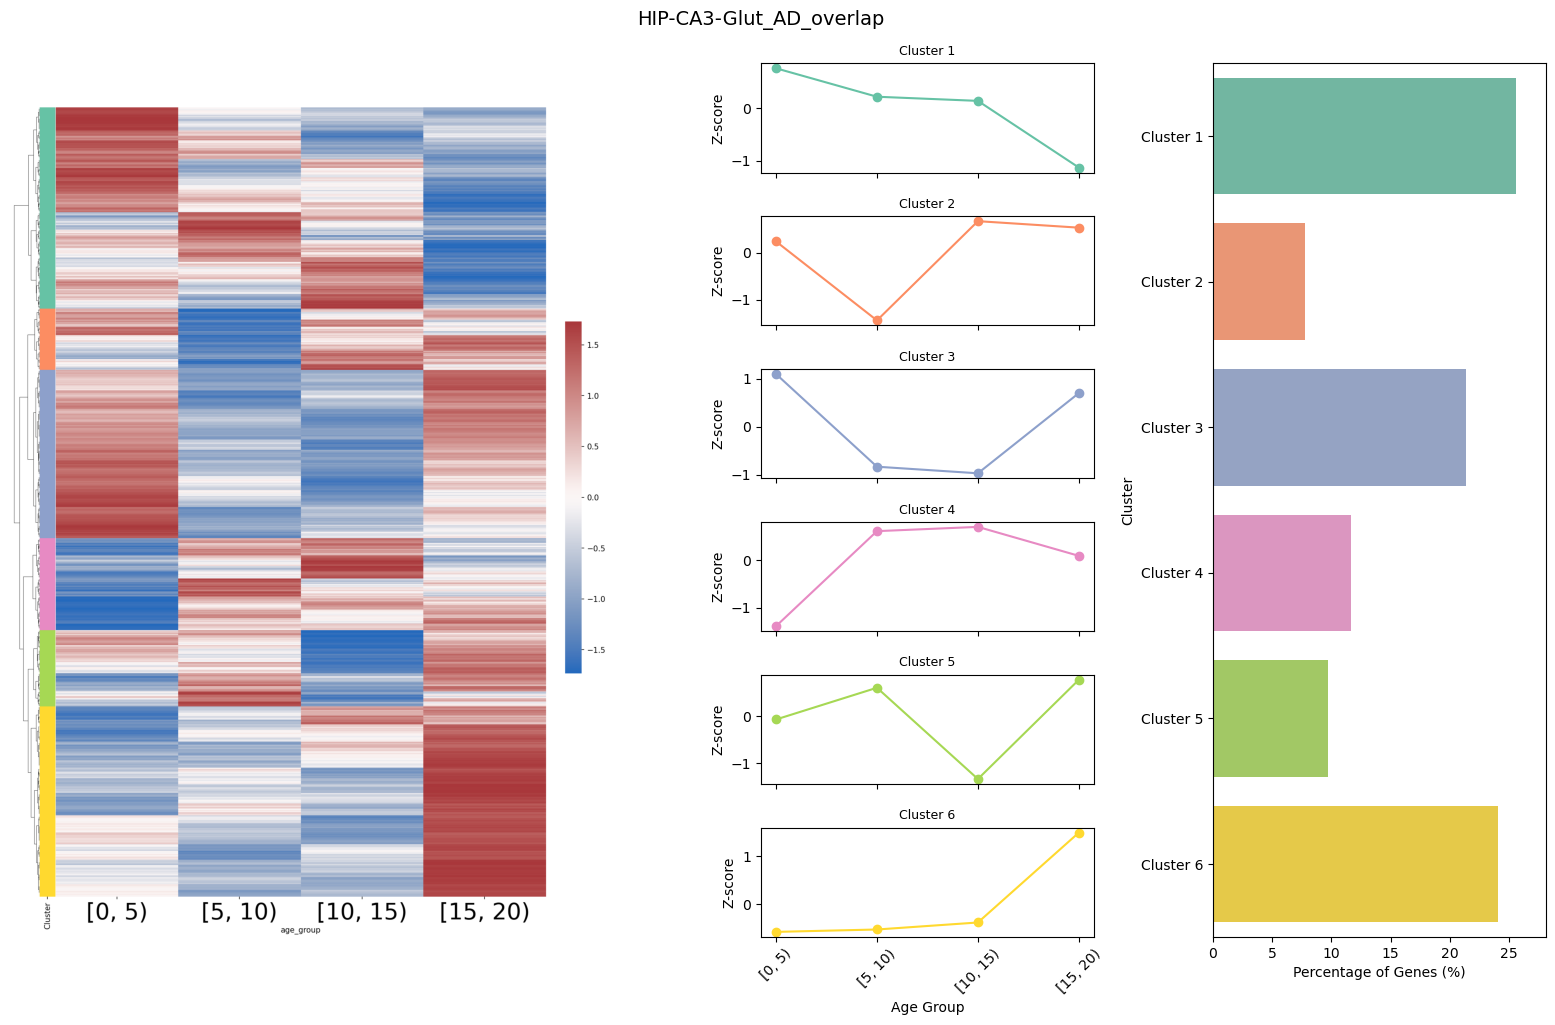

In [67]:
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import zscore
from scipy.cluster.hierarchy import linkage, fcluster
from io import BytesIO
from PIL import Image
from matplotlib.gridspec import GridSpec
plt.rcParams['pdf.fonttype'] = 42
plt.rcParams['font.family'] = 'sans-serif'

# -----------------------------
# Input: individual_avg (age_group x genes)
# -----------------------------
# Step 1: Z-score scale gene expression (column-wise)
scaled_data = individual_avg.apply(zscore, axis=0)

# Step 2: Cluster genes using Ward linkage
Z = linkage(scaled_data.T, method='ward')
max_clusters = 6
column_clusters = fcluster(Z, max_clusters, criterion='maxclust')

# Step 3: Cluster annotation and color palette
cluster_map = pd.Series(column_clusters, index=scaled_data.columns)
col_cluster_df = pd.DataFrame({'Cluster': column_clusters}, index=scaled_data.columns)
palette = sns.color_palette("Set2", n_colors=max_clusters)
cluster_colors = cluster_map.map(lambda x: palette[x - 1])
row_colors = pd.DataFrame({'Cluster': cluster_colors}, index=scaled_data.columns)  # renamed to row_colors after transpose

# Step 4: Create clustermap (transpose so genes are rows), save as rotated image
g=sns.clustermap(scaled_data.T,
               cmap="vlag",
               row_cluster=True,
               col_cluster=False,
               method="ward",
               row_colors=row_colors,  
               yticklabels=False,
               dendrogram_ratio=(0.05, 0.05),
               figsize=(10, 16),
                cbar_pos=(1.02, 0.3, 0.03, 0.4))
g.ax_heatmap.tick_params(axis='x', labelsize=30)  # x-axis labels (columns)
#g.ax_heatmap.tick_params(axis='y', labelsize=50)  # y-axis labels (rows)

#g.ax_heatmap.set_title("Gene Expression Heatmap")
buf = BytesIO()
g.fig.savefig(buf, format='png', bbox_inches='tight',pad_inches=0.05, dpi=150)
plt.close(g.fig)
buf.seek(0)
heatmap_img = Image.open(buf) 
#heatmap_img = heatmap_img.crop((20, 20, heatmap_img.width - 20, heatmap_img.height - 20))

# Step 5: Compute average expression per cluster across age groups
cluster_means = pd.DataFrame(index=scaled_data.index)
for cluster_id in sorted(cluster_map.unique()):
    genes = cluster_map[cluster_map == cluster_id].index
    cluster_means[f"Cluster {cluster_id}"] = scaled_data[genes].mean(axis=1)

# Convert age_group to string if it's IntervalIndex
cluster_means.index = cluster_means.index.astype(str)
df_plot = cluster_means.copy()
cluster_labels = sorted(df_plot.columns)
color_map = {label: palette[int(label.split()[-1]) - 1] for label in cluster_labels}

# Step 6: Barplot data
cluster_counts = cluster_map.value_counts().sort_index()
cluster_percent = 100 * cluster_counts / cluster_counts.sum()
bar_colors = [palette[i - 1] for i in cluster_percent.index]

# Step 7: Set up the full figure (1 row, 3 columns)
fig = plt.figure(figsize=(16, 10))
gs = GridSpec(nrows=1, ncols=3, width_ratios=[2, 1, 1], figure=fig)

# --- Column 1: Heatmap image ---
ax0 = fig.add_subplot(gs[0])
ax0.imshow(heatmap_img)
#ax0.set_aspect('auto')  # allow resizing to match others
ax0.axis('off')
#ax0.set_title("Gene Expression Heatmap", fontsize=10)

# --- Column 2: 6 stacked line plots (one per cluster) ---
inner_gs = gs[1].subgridspec(nrows=max_clusters, ncols=1, hspace=0.4)
for i, cluster in enumerate(cluster_labels):
    ax = fig.add_subplot(inner_gs[i])
    ax.plot(df_plot.index, df_plot[cluster], marker='o', color=color_map[cluster])
    ax.set_title(cluster, fontsize=9)
    ax.set_ylabel("Z-score")
    if i == max_clusters - 1:
        ax.set_xlabel("Age Group")
        ax.tick_params(axis='x', rotation=45)
    else:
        ax.tick_params(labelbottom=False)
    ax.grid(False)

# --- Column 3: Horizontal bar plot of gene percentages ---
ax2 = fig.add_subplot(gs[2])
sns.barplot(y=cluster_percent.index.map(lambda x: f"Cluster {x}"),
            x=cluster_percent.values,
            palette=bar_colors,
            ax=ax2)
ax2.set_xlabel("Percentage of Genes (%)")
ax2.set_ylabel("Cluster")
#ax2.set_title("Gene Distribution", fontsize=10)
ax2.set_xlim(0, max(cluster_percent.values) * 1.1)

# --- Final layout ---
plt.tight_layout()
plt.suptitle(f"{ct}_AD_overlap", y=1.02, fontsize=14)
#plt.show()
plt.savefig(f'./figures/AD/{ct}_ad_overlap.pdf',bbox_inches='tight',format='pdf')

## region specific

In [12]:
#average individuals within age groups
# Convert to DataFrame for easy grouping (optional, but clearer)
bins=[0,5,10,15,21]
#labels=
adata.obs['age_group'] = pd.cut(adata.obs['age'], bins=bins, right=False)
subset = adata#[adata.obs['age']>3,:]
df_expr = pd.DataFrame(subset.X.toarray() if hasattr(adata.X, 'toarray') else subset.X,
                       index=subset.obs_names,
                       columns=subset.var_names)
# Add metadata
df_expr['animal_id'] = subset.obs['animal_id'].values
df_expr['age_group'] = subset.obs['age_group'].values
df_expr['region'] = subset.obs['region'].values
df_expr['age'] = subset.obs['age'].values


#Add additional region filter for neuronal subtypes
df_expr['region'].value_counts()

region
ACC      51
mdTN     50
EC       49
HIP      48
NAc      48
CN       46
dlPFC    41
MB       41
M1       40
IPP      38
lCb      32
Name: count, dtype: int64

In [13]:
adata.obs.groupby(['age_group', 'animal_id']).size().reset_index(name='count') \
    .query('count > 0') \
    .groupby('age_group')['animal_id'].nunique()

age_group
[0, 5)      11
[5, 10)     15
[10, 15)    16
[15, 21)    13
Name: animal_id, dtype: int64

In [14]:
num_animals = 20
df_expr = df_expr.groupby('region').filter(lambda x: len(x) >= num_animals)

In [52]:
all_avgs = []  # store each region-specific individual_avg

for region in df_expr['region'].unique():
    subset = df_expr[df_expr['region'] == region]
    
    # Compute average per age_group for first N columns (genes)
    individual_avg = subset.groupby('age_group').apply(lambda x: x.iloc[:, :num_genes].mean())
    
    # Rename columns to include region prefix
    individual_avg.columns = [f"{region}_{col}" for col in individual_avg.columns]

    #Exclude columns with all 0 (or lowly expressed_genes)
    individual_avg = individual_avg.drop(columns=individual_avg.columns[(individual_avg == 0).all()])
    
    # Append to list
    all_avgs.append(individual_avg)

# Concatenate all by columns (i.e., wide format)
combined_avg = pd.concat(all_avgs, axis=1)
combined_avg.shape

(4, 200)

Text(0.5, 1.02, 'HIP-DG-Glut_AD_overlap_down')

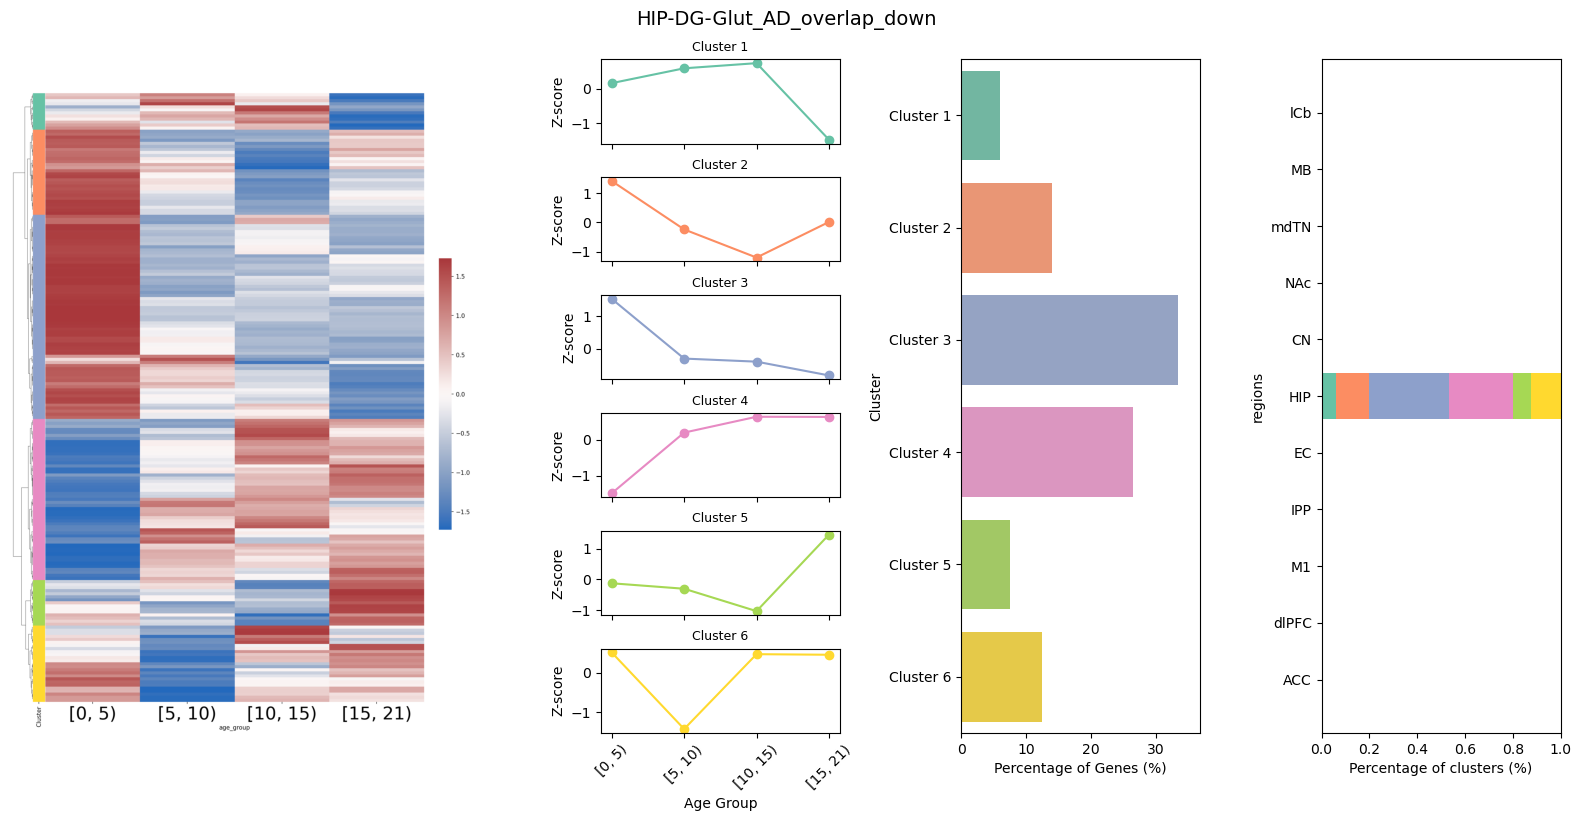

In [53]:
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import zscore
from scipy.cluster.hierarchy import linkage, fcluster
from io import BytesIO
from PIL import Image
from matplotlib.gridspec import GridSpec
plt.rcParams['pdf.fonttype'] = 42
plt.rcParams['font.family'] = 'sans-serif'

# -----------------------------
# Input: individual_avg (age_group x genes)
# -----------------------------
# Step 1: Z-score scale gene expression (column-wise)
scaled_data = combined_avg.apply(zscore, axis=0)

# Step 2: Cluster genes using Ward linkage
Z = linkage(scaled_data.T, method='ward')
max_clusters = 6
column_clusters = fcluster(Z, max_clusters, criterion='maxclust')

# Step 3: Cluster annotation and color palette
cluster_map = pd.Series(column_clusters, index=scaled_data.columns)
col_cluster_df = pd.DataFrame({'Cluster': column_clusters}, index=scaled_data.columns)
palette = sns.color_palette("Set2", n_colors=max_clusters)
cluster_colors = cluster_map.map(lambda x: palette[x - 1])
row_colors = pd.DataFrame({'Cluster': cluster_colors}, index=scaled_data.columns)  # renamed to row_colors after transpose

# Step 4: Create clustermap, save as image
g=sns.clustermap(scaled_data.T,
               cmap="vlag",
               row_cluster=True,
               col_cluster=False,
               method="ward",
               row_colors=row_colors,  
               yticklabels=False,
               dendrogram_ratio=(0.05, 0.05),
               figsize=(10, 16),
                cbar_pos=(1.02, 0.3, 0.03, 0.4))
g.ax_heatmap.tick_params(axis='x', labelsize=30)  # x-axis labels (columns)

buf = BytesIO()
g.fig.savefig(buf, format='png', bbox_inches='tight',pad_inches=0.05, dpi=150)
plt.close(g.fig)
buf.seek(0)
heatmap_img = Image.open(buf) 
#heatmap_img = heatmap_img.crop((20, 20, heatmap_img.width - 20, heatmap_img.height - 20))

# Step 5: Compute average expression per cluster to make lineplot
cluster_means = pd.DataFrame(index=scaled_data.index)
for cluster_id in sorted(cluster_map.unique()):
    genes = cluster_map[cluster_map == cluster_id].index
    cluster_means[f"Cluster {cluster_id}"] = scaled_data[genes].mean(axis=1)
# Convert age_group to string if it's IntervalIndex
cluster_means.index = cluster_means.index.astype(str)
df_plot = cluster_means.copy()
cluster_labels = sorted(df_plot.columns)
color_map = {label: palette[int(label.split()[-1]) - 1] for label in cluster_labels}

# Step 6: Compute per of genes per cluster to make barplot
cluster_counts = cluster_map.value_counts().sort_index()
cluster_percent = 100 * cluster_counts / cluster_counts.sum()
bar_colors = [palette[i - 1] for i in cluster_percent.index]

# Step 7: Compute per of regions per cluster to make barplot
temp = pd.DataFrame({'cluster': cluster_map.values, 'region': cluster_map.index.str.split('_').str[0]})
levels=['ACC','dlPFC','M1','IPP','EC','HIP','CN','NAc','mdTN','MB','lCb']
temp['region'] = pd.Categorical(temp['region'] , categories=levels, ordered=True)
counts = temp.groupby(['cluster', 'region']).size().reset_index(name='count')
counts['proportion'] = counts.groupby('region')['count'].transform(lambda x: x / x.sum())
stacked_df = counts.pivot(index='region', columns='cluster', values='proportion').fillna(0)
colors = palette  # or any other colormap
categories = stacked_df.columns
prefixes = stacked_df.index


# Step 8: Set up the full figure (1 row, 3 columns)
fig = plt.figure(figsize=(16, 8))
gs = GridSpec(nrows=1, ncols=4, width_ratios=[2, 1, 1, 1], figure=fig)

# --- Column 1: Heatmap image ---
ax0 = fig.add_subplot(gs[0])
ax0.imshow(heatmap_img)
ax0.axis('off')

# --- Column 2: 6 stacked line plots (one per cluster) ---
inner_gs = gs[1].subgridspec(nrows=max_clusters, ncols=1, hspace=0.4)
for i, cluster in enumerate(cluster_labels):
    ax = fig.add_subplot(inner_gs[i])
    ax.plot(df_plot.index, df_plot[cluster], marker='o', color=color_map[cluster])
    ax.set_title(cluster, fontsize=9)
    ax.set_ylabel("Z-score")
    if i == max_clusters - 1:
        ax.set_xlabel("Age Group")
        ax.tick_params(axis='x', rotation=45)
    else:
        ax.tick_params(labelbottom=False)
    ax.grid(False)

# --- Column 3: Horizontal bar plot of gene percentages ---
ax2 = fig.add_subplot(gs[2])
sns.barplot(y=cluster_percent.index.map(lambda x: f"Cluster {x}"),
            x=cluster_percent.values,
            palette=bar_colors,
            ax=ax2)
ax2.set_xlabel("Percentage of Genes (%)")
ax2.set_ylabel("Cluster")
ax2.set_xlim(0, max(cluster_percent.values) * 1.1)

# --- Column 4: Horizontal bar plot of region percentages ---
ax3 = fig.add_subplot(gs[3])  
left = np.zeros(len(stacked_df))
for i, cat in enumerate(categories):
    ax3.barh(prefixes, stacked_df[cat], left=left, label=f"Category {cat}", 
             color=colors[i % len(colors)])
    left += stacked_df[cat].values
ax3.set_xlabel("Percentage of clusters (%)")
ax3.set_ylabel("regions")
ax3.set_xlim(0, 1)

# --- Final layout ---
plt.tight_layout()
plt.suptitle(f"{ct}_AD_overlap_{direction}", y=1.02, fontsize=14)
#plt.show()
#plt.savefig(f'./figures/AD/{ct}_ad_overlap_{group}_regions_filtered_{direction}_specific.pdf',bbox_inches='tight',format='pdf')

## LOESS

In [55]:
import pandas as pd
import numpy as np
import statsmodels.api as sm

# Define prediction age grid
age_grid = np.linspace(1, 20, 191)  # e.g., from 1.0 to 20.0 in 0.1-year steps

# Columns to smooth (exclude metadata)
expr_cols = df_expr.columns.difference(['animal_id', 'age_group', 'region', 'age'])

# Prepare DataFrame to store LOESS-smoothed values
loess_grid = pd.DataFrame(index=age_grid, columns=expr_cols)

# Fit LOESS and interpolate for each gene
for gene in expr_cols:
    # Drop rows with missing values
    data = df_expr[[gene, 'age']].dropna()
    data_sorted = data.sort_values('age')

    # Fit LOESS model
    loess_result = sm.nonparametric.lowess(
        endog=data_sorted[gene],
        exog=data_sorted['age'],
        frac=0.3,
        return_sorted=True
    )

    # Interpolate predictions on the fixed age grid
    interp_vals = np.interp(age_grid, loess_result[:, 0], loess_result[:, 1])
    loess_grid[gene] = interp_vals

# Final formatting
loess_grid.index.name = 'age'
loess_grid.reset_index(inplace=True)
loess_z = loess_grid.copy()
gene_cols = [col for col in loess_z.columns if col != 'age']

# Apply z-score normalization to gene columns
loess_z[gene_cols] = loess_z[gene_cols].apply(zscore, axis=0)


/tmp/ipykernel_324343/1743577221.py:34: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  loess_grid.reset_index(inplace=True)


In [62]:
import numpy as np

# Min-max normalization
loess_minmax = (loess_grid.set_index('age') - loess_grid.set_index('age').min()) / \
               (loess_grid.set_index('age').max() - loess_grid.set_index('age').min())
loess_minmax.reset_index(inplace=True)

# Find row index closest to age 4
age_ref_idx = np.abs(loess_minmax.index.values - 4.0).argmin()

# Subtract expression at age 4
ref_values = loess_minmax.iloc[age_ref_idx]
loess_centered = loess_minmax - ref_values

# Reset index for plotting or export
loess_centered.reset_index(inplace=True)


/tmp/ipykernel_324343/1666443652.py:6: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  loess_minmax.reset_index(inplace=True)
/tmp/ipykernel_324343/1666443652.py:16: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  loess_centered.reset_index(inplace=True)


/home/wyang114/.conda/envs/TACCO_env/lib/python3.11/site-packages/seaborn/matrix.py:560: UserWarning: Clustering large matrix with scipy. Installing `fastcluster` may give better performance.
  warnings.warn(msg)


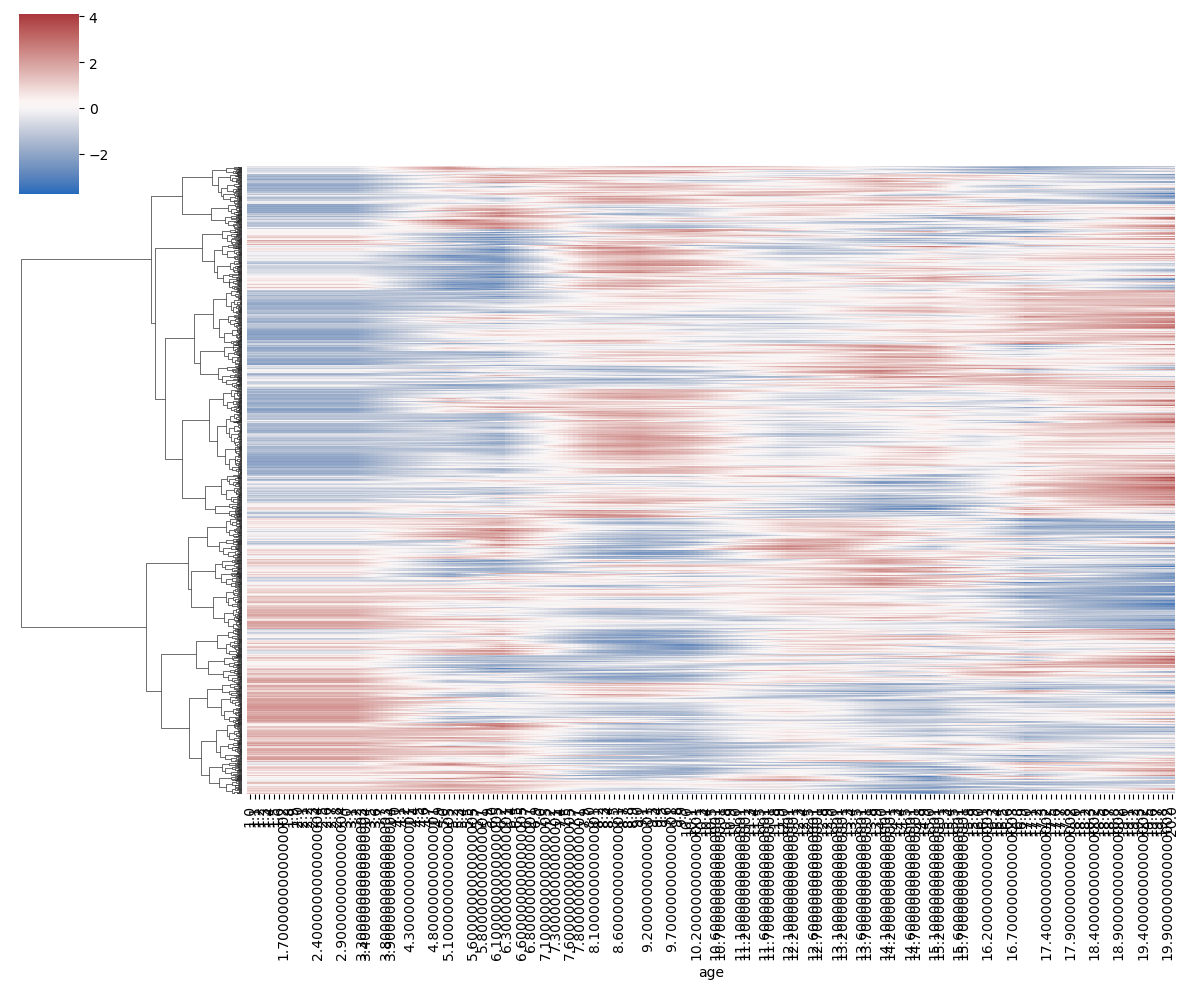

In [64]:
import seaborn as sns
import matplotlib.pyplot as plt

loess_mat = loess_z

# Set 'age' as the index (rows = age, columns = genes)
loess_mat= loess_mat.dropna(axis=1)
loess_mat_indexed = loess_mat.set_index('age')

# Plot clustered heatmap
sns.clustermap(loess_mat_indexed.T,  # transpose so genes are clustered (rows)
               cmap='vlag',
               method="ward",
               figsize=(12, 10),
               col_cluster=False,  # optional: keep age order fixed
               yticklabels=False,
               xticklabels=True)

plt.show()


## TROUBLESHOOT

In [53]:
geneset_1 = cluster_map[cluster_map == 5].index.str.replace(r'^.*?_', '', regex=True)
df_geneset1 = df_subset.loc[df_subset['gene'].isin(geneset_1),]

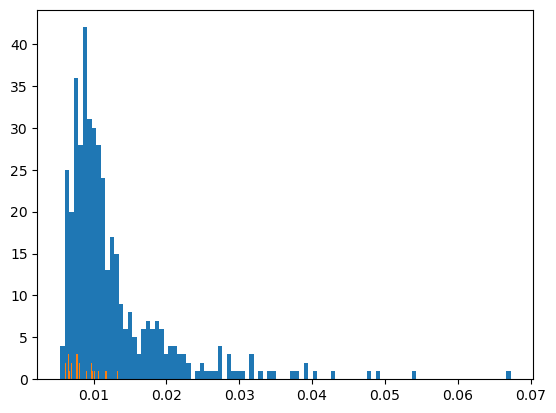

In [54]:
plt.hist(df_subset['logFC_age'],bins=100);
plt.hist(df_geneset1['logFC_age'],bins=100);

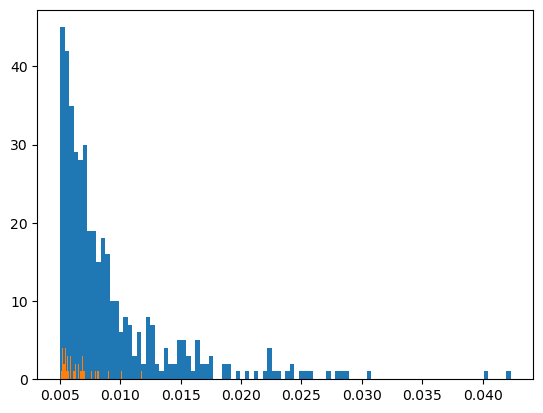

In [55]:
plt.hist(df_subset['age_mashr_pm'],bins=100);
plt.hist(df_geneset1['age_mashr_pm'],bins=100);

In [ ]:
stacked_df.loc['All'] = cluster_percent/100
stacked_df.to_csv(f'./data/AD/{ct}_perc.csv')

In [162]:
import pandas as pd
import scipy.stats as stats

observed_df = counts.pivot(index='region', columns='cluster', values='count').fillna(0)
# Step 1: Normalize expected frequencies
expected_probs = pd.Series(cluster_percent)
expected_probs /= expected_probs.sum()
# Your df with observed proportions
#n_trials = 1000  # or region-specific if known

results = []

for region in observed_df.index:
    for cluster in observed_df.columns:
        k = observed_df.loc[region, cluster]
        p_exp = expected_probs[int(cluster)]
        n_trials = observed_df.loc[region,:].sum()
        # Two-sided binomial test
        pval = stats.binom_test(k, n_trials, p_exp, alternative='two-sided')
        results.append({
            'region': region,
            'cluster': cluster,
            'observed_prop': k/n_trials,
            'expected_prop': p_exp,
            'pval': pval
        })

# Convert to DataFrame
binom_results = pd.DataFrame(results)
binom_results['cell_type']=ct
binom_results.to_csv(f'./data/AD/{ct}_binom_test.csv')

/tmp/ipykernel_3415021/3939109463.py:19: DeprecationWarning: 'binom_test' is deprecated in favour of 'binomtest' from version 1.7.0 and will be removed in Scipy 1.12.0.
  pval = stats.binom_test(k, n_trials, p_exp, alternative='two-sided')
/tmp/ipykernel_3415021/3939109463.py:23: RuntimeWarning: invalid value encountered in scalar divide
  'observed_prop': k/n_trials,


In [163]:
binom_results.loc[binom_results['pval']<2.2e-16,:] 

,region,cluster,observed_prop,expected_prop,pval,cell_type


## check with single cell

In [5]:
processed_dir = '/scratch/nsnyderm/u01/intermediate_files/cell-class_h5ad_update/'
os.listdir(processed_dir)
file = 'Res1_glutamatergic-neurons_update.h5ad'
adata_sc = sc.read_h5ad(processed_dir+file)

In [24]:
bins=[0,3,6,9,12,15,21]
subset = adata_sc[:,adata_sc.var['external_gene_name'].isin(geneset)]
louvain_list = [s.split('_')[-1] for s in subtype_list]
print(louvain_list)
subset.obs['age_bin']=pd.cut(subset.obs['age'], bins=bins)
subset = subset[(subset.obs['louvain'].isin(louvain_list)) & (subset.obs['region'].isin(region_list)),:] #filter for subtype

##For balanced cell counts
#group_counts = subset.obs.groupby("age_bin").size()
#median_count = int(group_counts.median())
#median_count=3000
# df_balanced = (
#     subset.obs.groupby("age_bin", group_keys=False)
#       .apply(lambda x: x.sample(n=min(len(x), median_count), random_state=42))
# )
# subset = subset[df_balanced.index,:]


df_mat = pd.DataFrame(subset.X.toarray(), columns=subset.var['external_gene_name'].tolist())
row_sums = df_mat.sum(axis=1)
df_norm = df_mat.div(row_sums, axis=0)
df_norm *= 10000
df_log = np.log1p(df_norm)
df_log = df_log.loc[:,~df_log.columns.duplicated(keep=False)] #filter out one human-to-many macaque orthologs

df_log['age']=subset.obs['age'].values
df_log['age_bin'] = subset.obs['age_bin'].values
df_log['region']=subset.obs['region'].tolist()
df_mean = df_log.drop('age',axis=1).groupby(['age_bin','region']).mean().reset_index()
mat_list = []
for rg in df_log['region'].unique()[0:]:
    temp = df_mean.loc[df_mean['region']==rg,:]
    temp = temp.set_index('age_bin')
    temp=temp.drop('region',axis=1)
    temp.columns = [rg+'_'+cl for cl in temp.columns]
    mat_list.append(temp.T)
df_combined = pd.concat(mat_list, axis=0)
df_z = df_combined.apply(zscore, axis=1)

['9']


/tmp/ipykernel_2604034/627936328.py:5: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  subset.obs['age_bin']=pd.cut(subset.obs['age'], bins=bins)


/home/wyang114/.conda/envs/TACCO_env/lib/python3.11/site-packages/sklearn/cluster/_kmeans.py:1412: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  super()._check_params_vs_input(X, default_n_init=10)


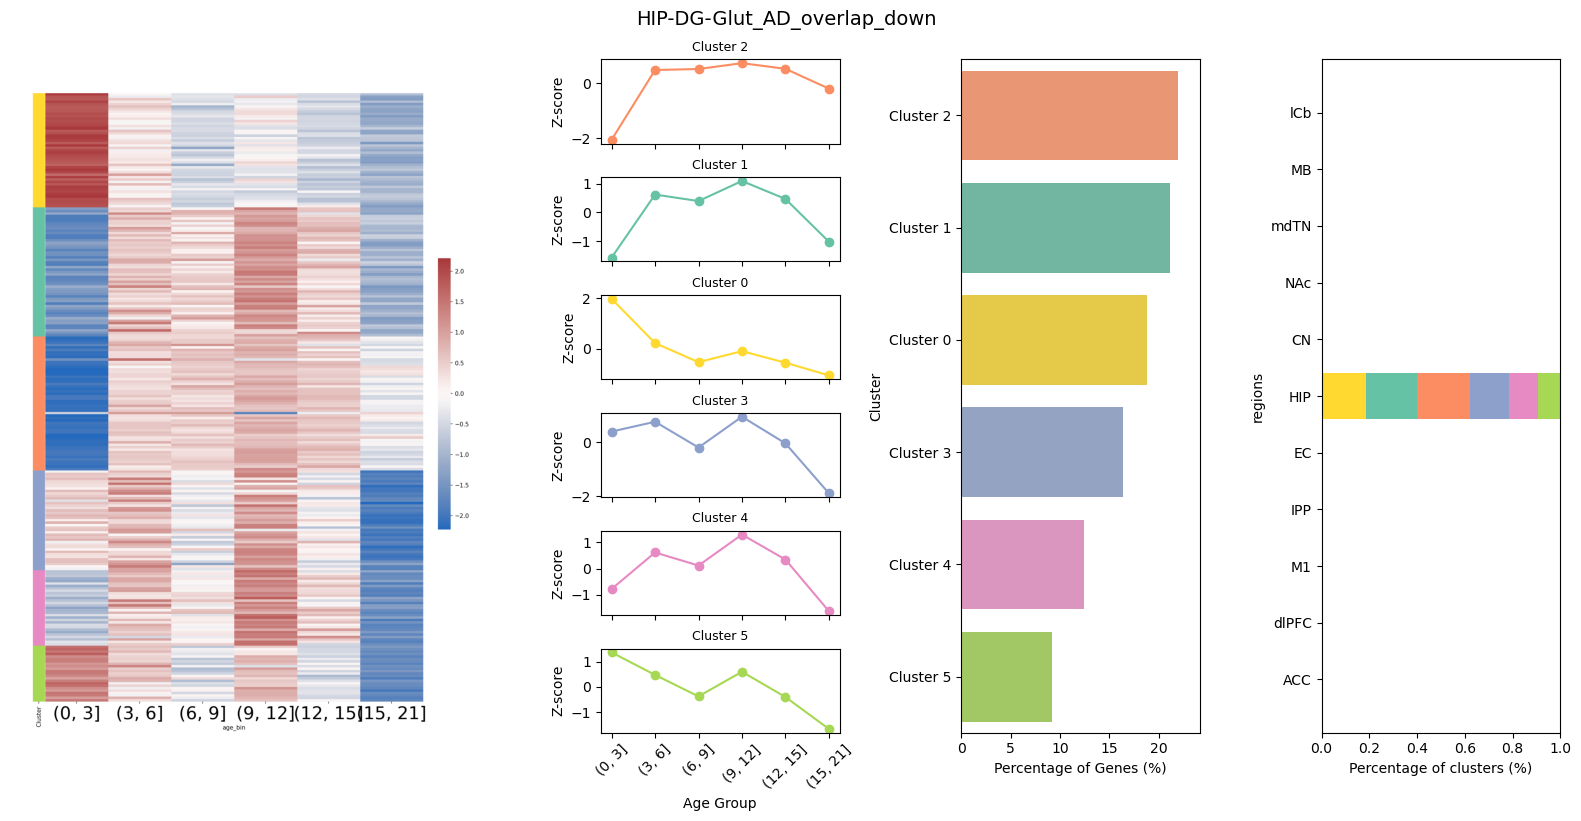

In [25]:
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import zscore
from scipy.cluster.hierarchy import linkage, fcluster
from io import BytesIO
from PIL import Image
from matplotlib.gridspec import GridSpec
from sklearn.cluster import KMeans
plt.rcParams['pdf.fonttype'] = 42
plt.rcParams['font.family'] = 'sans-serif'

# -----------------------------
# Input: individual_avg (age_group x genes)
# -----------------------------
scaled_data  = df_z.T
# Step 2: Cluster genes using Ward linkage
#Z = linkage(df_z, method='ward')
max_clusters = 6
#column_clusters = fcluster(Z, max_clusters, criterion='maxclust')

# Run KMeans clustering
kmeans = KMeans(n_clusters=max_clusters, random_state=42)
column_clusters = kmeans.fit_predict(df_z)
cluster_series = pd.Series(column_clusters, index=df_z.index, name='cluster')
sorted_rows = cluster_series.sort_values().index
df_z_sorted = df_z.loc[sorted_rows,:]

# Step 3: Cluster annotation and color palette
cluster_map = pd.Series(column_clusters, index=scaled_data.columns)
col_cluster_df = pd.DataFrame({'Cluster': column_clusters}, index=scaled_data.columns)
palette = sns.color_palette("Set2", n_colors=max_clusters)
cluster_colors = cluster_map.map(lambda x: palette[x - 1])
row_colors = pd.DataFrame({'Cluster': cluster_colors}, index=scaled_data.columns)  # renamed to row_colors after transpose

# Step 4: Create clustermap, save as image
g=sns.clustermap(#df_z,
                 df_z_sorted,
               cmap="vlag",
               row_cluster=False,
               col_cluster=False,
               #method="ward",
               row_colors=row_colors,  
               yticklabels=False,
               dendrogram_ratio=(0.05, 0.05),
               figsize=(10, 16),
                cbar_pos=(1.02, 0.3, 0.03, 0.4))
g.ax_heatmap.tick_params(axis='x', labelsize=30)  # x-axis labels (columns)

buf = BytesIO()
g.fig.savefig(buf, format='png', bbox_inches='tight',pad_inches=0.05, dpi=150)
plt.close(g.fig)
buf.seek(0)
heatmap_img = Image.open(buf) 
#heatmap_img = heatmap_img.crop((20, 20, heatmap_img.width - 20, heatmap_img.height - 20))

# Step 5: Compute average expression per cluster to make lineplot
cluster_means = pd.DataFrame(index=scaled_data.index)
for cluster_id in sorted(cluster_map.unique()):
    genes = cluster_map[cluster_map == cluster_id].index
    cluster_means[f"Cluster {cluster_id}"] = scaled_data[genes].mean(axis=1)
# Convert age_group to string if it's IntervalIndex
cluster_means.index = cluster_means.index.astype(str)
df_plot = cluster_means.copy()
cluster_labels = sorted(df_plot.columns)
color_map = {label: palette[int(label.split()[-1]) - 1] for label in cluster_labels}

# Step 6: Compute per of genes per cluster to make barplot
cluster_counts = cluster_map.value_counts().sort_index()
cluster_percent = 100 * cluster_counts / cluster_counts.sum()
bar_colors = [palette[i - 1] for i in cluster_percent.index]

# Step 7: Compute per of regions per cluster to make barplot
temp = pd.DataFrame({'cluster': cluster_map.values, 'region': cluster_map.index.str.split('_').str[0]})
levels=['ACC','dlPFC','M1','IPP','EC','HIP','CN','NAc','mdTN','MB','lCb']
temp['region'] = pd.Categorical(temp['region'] , categories=levels, ordered=True)
counts = temp.groupby(['cluster', 'region']).size().reset_index(name='count')
counts['proportion'] = counts.groupby('region')['count'].transform(lambda x: x / x.sum())
stacked_df = counts.pivot(index='region', columns='cluster', values='proportion').fillna(0)
colors = palette  # or any other colormap
categories = stacked_df.columns
prefixes = stacked_df.index


# Step 8: Set up the full figure (1 row, 3 columns)
fig = plt.figure(figsize=(16, 8))
gs = GridSpec(nrows=1, ncols=4, width_ratios=[2, 1, 1, 1], figure=fig)

# --- Column 1: Heatmap image ---
ax0 = fig.add_subplot(gs[0])
ax0.imshow(heatmap_img)
ax0.axis('off')

# --- Column 2: 6 stacked line plots (one per cluster) ---
inner_gs = gs[1].subgridspec(nrows=max_clusters, ncols=1, hspace=0.4)
order = cluster_percent.sort_values(ascending=False).index

for i, cluster in enumerate([cluster_labels[i] for i in order]):
    ax = fig.add_subplot(inner_gs[i])
    ax.plot(df_plot.index, df_plot[cluster], marker='o', color=color_map[cluster])
    ax.set_title(cluster, fontsize=9)
    ax.set_ylabel("Z-score")
    if i == max_clusters - 1:
        ax.set_xlabel("Age Group")
        ax.tick_params(axis='x', rotation=45)
    else:
        ax.tick_params(labelbottom=False)
    ax.grid(False)

# --- Column 3: Horizontal bar plot of gene percentages ---
ax2 = fig.add_subplot(gs[2])
sns.barplot(y=cluster_percent.sort_values(ascending=False).index.map(lambda x: f"Cluster {x}"),
            x=cluster_percent.sort_values(ascending=False).values,
            palette=[bar_colors[i] for i in order],
            ax=ax2)
ax2.set_xlabel("Percentage of Genes (%)")
ax2.set_ylabel("Cluster")
ax2.set_xlim(0, max(cluster_percent.values) * 1.1)

# --- Column 4: Horizontal bar plot of region percentages ---
ax3 = fig.add_subplot(gs[3])  
left = np.zeros(len(stacked_df))
for i, cat in enumerate(categories):
    ax3.barh(prefixes, stacked_df[cat], left=left, label=f"Category {cat}", 
             color=bar_colors[i % len(bar_colors)])
    left += stacked_df[cat].values
ax3.set_xlabel("Percentage of clusters (%)")
ax3.set_ylabel("regions")
ax3.set_xlim(0, 1)

# --- Final layout ---
plt.tight_layout()
plt.suptitle(f"{ct}_AD_overlap_{direction}", y=1.02, fontsize=14)
#plt.show()
plt.savefig(f'./figures/AD-KMEANS/{ct}_ad_overlap_{group}_regions_filtered_{direction}_sc_0.001.pdf',bbox_inches='tight',format='pdf')
cluster_series.to_csv(f'./data/AD/{ct}_gene_clusters_{direction}.csv')

In [9]:
subset.obs['age_bin'] = pd.cut(subset.obs['age'], bins=bins)
subset.obs['age_bin'].value_counts()

/tmp/ipykernel_3947946/2618613092.py:1: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  subset.obs['age_bin'] = pd.cut(subset.obs['age'], bins=bins)


age_bin
(3, 6]      5272
(9, 12]     3417
(6, 9]      3255
(12, 15]    3168
(15, 21]    2951
(0, 3]       485
Name: count, dtype: int64

<Axes: xlabel='region', ylabel='count'>

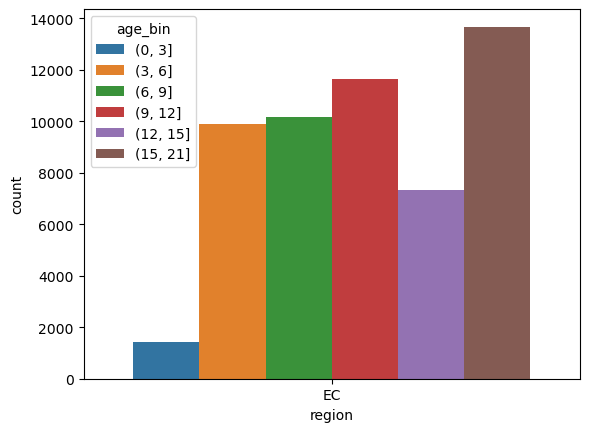

In [9]:
df = subset.obs.groupby(['age_bin','region']).size().reset_index(name='count')
sns.barplot(data=df, x='region', y='count', hue='age_bin')